## Lukemia preprocessing

In [1]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler

# ============================================================
# 1. Load Lukemia Dataset
# ============================================================

file_path = "../data/preprocessed/ALLAML.csv"

df = pd.read_csv(file_path)


# ============================================================
# 2. Separate Features and Labels
# ============================================================

X_raw = df.drop(
    columns=["label"]
).values

y = df["label"].values


# ============================================================
# 3. Standardization
# ============================================================

scaler = StandardScaler()

X_scaled = scaler.fit_transform(
    X_raw
)


# ============================================================
# 4. Matrix Formatting
# Paper notation: X ∈ R^(d × n)
# ============================================================

X = X_scaled.T


# ============================================================
# 5. Verification
# ============================================================

print("--- Lukemia Data Preprocessing Summary ---")

print(
    f"Original DataFrame Shape : {df.shape}"
)

print(
    f"Raw Feature Matrix Shape : {X_raw.shape}"
)

print(
    f"Final X Shape            : {X.shape}"
)

print(
    f"Label Shape              : {y.shape}"
)

print(
    f"Number of Features (d)   : {X.shape[0]}"
)

print(
    f"Number of Samples (n)    : {X.shape[1]}"
)

print(
    f"Unique Classes            : {len(np.unique(y))}"
)

print(
    f"Missing Values in X       : {np.isnan(X).sum()}"
)

print(
    f"Missing Values in y       : {np.isnan(y).sum()}"
)

--- Lukemia Data Preprocessing Summary ---
Original DataFrame Shape : (72, 7130)
Raw Feature Matrix Shape : (72, 7129)
Final X Shape            : (7129, 72)
Label Shape              : (72,)
Number of Features (d)   : 7129
Number of Samples (n)    : 72
Unique Classes            : 2
Missing Values in X       : 0
Missing Values in y       : 0


## Graph Laplacian

In [2]:
# ============================================================
# Cell 2: Task 2 — Graph Laplacian Construction
# ============================================================

import numpy as np
from sklearn.metrics import pairwise_distances


# ============================================================
# 1. Parameters
# ============================================================

k = 5


# ============================================================
# 2. Pairwise Euclidean Distances
# X = (1024, 400)
# X.T = (400, 1024)
# ============================================================

dist_matrix = pairwise_distances(
    X.T,
    metric="euclidean"
)


# ============================================================
# 3. Heat Kernel Affinity Matrix
# ============================================================

n_samples = X.shape[1]

S = np.zeros(
    (n_samples, n_samples),
    dtype=np.float64
)

# Heat-kernel bandwidth
sigma = np.mean(dist_matrix)

# Safety check
if sigma <= 0:
    raise ValueError(
        "Sigma must be greater than zero."
    )


for i in range(n_samples):

    # k nearest neighbours + self
    knn_indices = np.argsort(
        dist_matrix[i]
    )[:k + 1]

    for j in knn_indices:

        # Exclude the sample itself
        if i != j:

            sim = np.exp(
                -(
                    dist_matrix[i, j] ** 2
                ) / (
                    2.0 * sigma ** 2
                )
            )

            S[i, j] = sim

            # Make affinity symmetric
            S[j, i] = sim


# Ensure zero diagonal
np.fill_diagonal(
    S,
    0.0
)


# ============================================================
# 4. Degree Matrix
# ============================================================

D = np.diag(
    np.sum(S, axis=1)
)


# ============================================================
# 5. Graph Laplacian
# L_X = D - S
# ============================================================

L_X = D - S


# ============================================================
# 6. Verification
# ============================================================

print("--- Task 2: Graph Laplacian Summary ---")

print(
    f"Pairwise Distance Matrix Shape: "
    f"{dist_matrix.shape}"
)

print(
    f"Affinity Matrix S Shape: "
    f"{S.shape}"
)

print(
    f"Graph Laplacian L_X Shape: "
    f"{L_X.shape}"
)

print(
    f"Sigma: {sigma:.6f}"
)

print(
    f"Is S Symmetric? : "
    f"{np.allclose(S, S.T)}"
)

print(
    f"Is L_X Symmetric? : "
    f"{np.allclose(L_X, L_X.T)}"
)

print(
    f"Max value in L_X: "
    f"{np.max(L_X):.4f}"
)

print(
    f"Min value in L_X: "
    f"{np.min(L_X):.4f}"
)

print(
    f"NaN values in L_X: "
    f"{np.isnan(L_X).sum()}"
)

--- Task 2: Graph Laplacian Summary ---
Pairwise Distance Matrix Shape: (72, 72)
Affinity Matrix S Shape: (72, 72)
Graph Laplacian L_X Shape: (72, 72)
Sigma: 116.554870
Is S Symmetric? : True
Is L_X Symmetric? : True
Max value in L_X: 19.7680
Min value in L_X: -0.8399
NaN values in L_X: 0


In [3]:
# Verify the Laplacian mathematically
print("Diagonal minimum:", np.diag(L_X).min())
print("Diagonal maximum:", np.diag(L_X).max())

eigenvalues = np.linalg.eigvalsh(L_X)

print("Minimum eigenvalue:", eigenvalues.min())
print("Maximum eigenvalue:", eigenvalues.max())
print("Near-zero eigenvalues:",
      np.sum(np.abs(eigenvalues) < 1e-6))
print("Row-sum error:",
      np.max(np.abs(L_X.sum(axis=1))))

Diagonal minimum: 2.1584742820026626
Diagonal maximum: 19.767967211671976
Minimum eigenvalue: -1.2975731600306517e-15
Maximum eigenvalue: 20.93818624442509
Near-zero eigenvalues: 1
Row-sum error: 3.552713678800501e-15


## SMFAE Training

In [4]:
import numpy as np

def train_smfae_stable(
    X, L_X, D, S,
    m=200,
    alpha=1e-4,
    beta=1e-4,
    gamma=5e-4,
    omega=0.01,
    lr=1e-4,
    epochs=500
):
    d, n = X.shape

    # 1. Weights Initialization
    np.random.seed(42)

    W1 = np.random.randn(m, d) * np.sqrt(2.0 / d)
    W2 = np.random.randn(d, m) * np.sqrt(2.0 / m)

    # Non-negative Auxiliary Matrix H
    H = np.abs(np.random.randn(m, n)) + 1e-5

    loss_history = []

    print(
        f"Starting Stable SMFAE Training on Lukemia Dataset "
        f"(d={d}, n={n}, m={m}, lr={lr})..."
    )

    for epoch in range(1, epochs + 1):

        # -------------------------
        # Forward Pass
        # -------------------------
        Z = W1 @ X
        X_hat = W2 @ Z

        # -------------------------
        # Losses
        # -------------------------

        # Reconstruction
        recon_err = X - X_hat
        loss_recon = 0.5 * np.sum(recon_err ** 2)

        # L2,1 Sparsity
        w1_norms = np.linalg.norm(W1, axis=1) + 1e-8
        loss_sparse = alpha * np.sum(w1_norms)

        # Weight Decay
        loss_weight_decay = (
            0.5 * beta * np.sum(W2 ** 2)
        )

        # Input Manifold
        loss_input_manifold = (
            0.5 * gamma *
            np.trace(Z @ L_X @ Z.T)
        )

        # Output Manifold
        output_diff = (H.T @ H) - L_X

        loss_output_manifold = (
            0.5 * omega *
            np.sum(output_diff ** 2)
        )

        # Total Loss
        total_loss = (
            loss_recon
            + loss_sparse
            + loss_weight_decay
            + loss_input_manifold
            + loss_output_manifold
        )

        loss_history.append(total_loss)

        # -------------------------
        # Gradients
        # -------------------------

        # W2
        grad_W2 = (
            -(recon_err @ Z.T)
            + beta * W2
        )

        # W1
        D_sparse = np.diag(
            1.0 / w1_norms
        )

        grad_W1_recon = (
            -(W2.T @ recon_err) @ X.T
        )

        grad_W1_sparse = (
            alpha * (D_sparse @ W1)
        )

        grad_W1_manifold = (
            gamma *
            (W1 @ X @ L_X @ X.T)
        )

        grad_W1 = (
            grad_W1_recon
            + grad_W1_sparse
            + grad_W1_manifold
        )

        # -------------------------
        # Gradient Clipping
        # -------------------------

        grad_W1 = np.clip(
            grad_W1,
            -10.0,
            10.0
        )

        grad_W2 = np.clip(
            grad_W2,
            -10.0,
            10.0
        )

        # -------------------------
        # Weight Updates
        # -------------------------

        W1 -= lr * grad_W1
        W2 -= lr * grad_W2

        # -------------------------
        # Stable H Update
        # -------------------------

        num_H = H @ D

        den_H = (
            H @ H.T @ H
            + H @ S
            + 1e-8
        )

        H = H * np.sqrt(
            np.maximum(
                num_H / den_H,
                1e-8
            )
        )

        # -------------------------
        # Progress
        # -------------------------

        if epoch % 100 == 0 or epoch == 1:
            print(
                f"Epoch [{epoch:3d}/{epochs}] | "
                f"Total Loss: {total_loss:12.2f} | "
                f"Recon: {loss_recon:12.2f} | "
                f"Input Manifold: "
                f"{loss_input_manifold:8.4f}"
            )

    return W1, W2, H, loss_history


# ==========================================
# Run Stable Training
# ==========================================

W1, W2, H, loss_history = train_smfae_stable(
    X,
    L_X,
    D,
    S,
    m=200,
    alpha=1e-4,
    beta=1e-4,
    gamma=5e-4,
    omega=0.01,
    lr=1e-4,
    epochs=500
)

Starting Stable SMFAE Training on Lukemia Dataset (d=7129, n=72, m=200, lr=0.0001)...
Epoch [  1/500] | Total Loss:   1669475.67 | Recon:   1245077.17 | Input Manifold:  27.8828
Epoch [100/500] | Total Loss:    794002.79 | Recon:    793991.31 | Input Manifold:   9.2611
Epoch [200/500] | Total Loss:    653842.92 | Recon:    653824.27 | Input Manifold:  16.4909
Epoch [300/500] | Total Loss:    679226.50 | Recon:    679206.42 | Input Manifold:  17.9700
Epoch [400/500] | Total Loss:    710423.42 | Recon:    710399.07 | Input Manifold:  22.2622
Epoch [500/500] | Total Loss:    655087.11 | Recon:    655060.65 | Input Manifold:  24.3972


In [5]:
import numpy as np
from sklearn.cluster import KMeans
from sklearn.metrics import normalized_mutual_info_score
from sklearn.preprocessing import StandardScaler
from scipy.optimize import linear_sum_assignment


def accuracy_score_hungarian(y_true, y_pred):
    """Calculate clustering accuracy using Hungarian Algorithm."""
    
    D = max(y_pred.max(), y_true.max()) + 1
    
    w = np.zeros((D, D), dtype=np.int64)
    
    for i in range(y_pred.size):
        w[y_pred[i], y_true[i]] += 1
    
    row_ind, col_ind = linear_sum_assignment(
        w.max() - w
    )
    
    return (
        w[row_ind, col_ind].sum()
        / y_pred.size
    )


# ==========================================
# 1. Feature Importance Ranking
# ==========================================

# W1 shape = (200, 1024)
# axis=0 calculates L2 norm for each feature/column

feature_scores = np.linalg.norm(
    W1,
    axis=0
)

# Descending order
ranked_feature_indices = np.argsort(
    feature_scores
)[::-1]


# ==========================================
# 2. Benchmark Settings
# ==========================================

r_subsets = [
    50, 100, 150, 200, 250, 300
]

n_classes = len(
    np.unique(y)
)

n_repetitions = 20


print(
    "--- Task 4: Lukemia Dataset Feature Selection "
    "& Clustering Evaluation ---"
)

print(
    f"{'Feature Count (r)':<20} | "
    f"{'Accuracy (ACC %)':<22} | "
    f"{'NMI (%)':<20}"
)

print("-" * 68)


results_lukemia = {}


# ==========================================
# 3. Feature Selection + K-Means
# ==========================================

for r in r_subsets:

    # Select top-r features
    top_r_indices = ranked_feature_indices[:r]

    # X shape = (1024, 400)
    # Transpose -> (400, r)
    X_selected = X[
        top_r_indices, :
    ].T

    # Standardize selected features
    X_selected_scaled = StandardScaler().fit_transform(
        X_selected
    )

    acc_list = []
    nmi_list = []

    # 20 K-Means repetitions
    for rep in range(n_repetitions):

        kmeans = KMeans(
            n_clusters=n_classes,
            n_init=10,
            random_state=rep
        )

        cluster_labels = kmeans.fit_predict(
            X_selected_scaled
        )

        # Hungarian Accuracy
        acc = (
            accuracy_score_hungarian(
                y,
                cluster_labels
            ) * 100
        )

        # NMI
        nmi = (
            normalized_mutual_info_score(
                y,
                cluster_labels
            ) * 100
        )

        acc_list.append(acc)
        nmi_list.append(nmi)

    # Mean and standard deviation
    mean_acc = np.mean(acc_list)
    std_acc = np.std(acc_list)

    mean_nmi = np.mean(nmi_list)
    std_nmi = np.std(nmi_list)

    results_lukemia[r] = {
        'ACC_mean': mean_acc,
        'ACC_std': std_acc,
        'NMI_mean': mean_nmi,
        'NMI_std': std_nmi
    }

    print(
        f"{r:<20} | "
        f"{mean_acc:6.2f} ± {std_acc:4.2f}%        | "
        f"{mean_nmi:6.2f} ± {std_nmi:4.2f}%"
    )

--- Task 4: Lukemia Dataset Feature Selection & Clustering Evaluation ---
Feature Count (r)    | Accuracy (ACC %)       | NMI (%)             
--------------------------------------------------------------------
50                   |  66.67 ± 3.93%        |   4.02 ± 2.17%
100                  |  65.00 ± 4.86%        |   4.20 ± 2.83%
150                  |  63.26 ± 7.01%        |   3.80 ± 4.88%
200                  |  58.06 ± 4.45%        |   5.02 ± 5.05%
250                  |  60.83 ± 5.24%        |  10.28 ± 4.95%
300                  |  67.29 ± 4.55%        |  14.99 ± 5.48%


## PNG Result

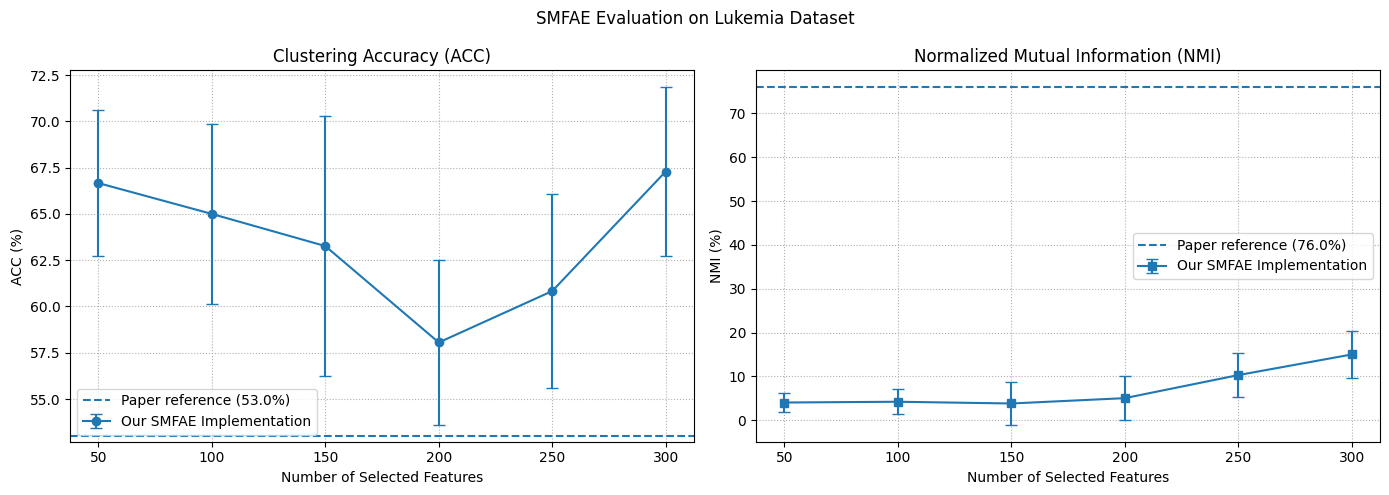

PNG generated from 6 actual experiment results.
Saved to: ../reports/figures/Lukemia_SMFAE_baseline_Results.png


In [6]:

import os
import numpy as np
import matplotlib.pyplot as plt

# Read results directly from the completed experiment
r_values = np.array(sorted(results_lukemia.keys()))

acc_means = np.array([
    results_lukemia[r]["ACC_mean"] for r in r_values
])
acc_stds = np.array([
    results_lukemia[r]["ACC_std"] for r in r_values
])
nmi_means = np.array([
    results_lukemia[r]["NMI_mean"] for r in r_values
])
nmi_stds = np.array([
    results_lukemia[r]["NMI_std"] for r in r_values
])

# Paper reference values: retain only if verified from the paper
paper_acc_baseline = 53.00
paper_nmi_baseline = 76.00

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].errorbar(
    r_values, acc_means, yerr=acc_stds,
    fmt="-o", capsize=4,
    label="Our SMFAE Implementation"
)
axes[0].axhline(
    paper_acc_baseline, linestyle="--",
    label=f"Paper reference ({paper_acc_baseline}%)"
)
axes[0].set(
    title="Clustering Accuracy (ACC)",
    xlabel="Number of Selected Features",
    ylabel="ACC (%)",
    xticks=r_values
)
axes[0].grid(True, linestyle=":")
axes[0].legend()

axes[1].errorbar(
    r_values, nmi_means, yerr=nmi_stds,
    fmt="-s", capsize=4,
    label="Our SMFAE Implementation"
)
axes[1].axhline(
    paper_nmi_baseline, linestyle="--",
    label=f"Paper reference ({paper_nmi_baseline}%)"
)
axes[1].set(
    title="Normalized Mutual Information (NMI)",
    xlabel="Number of Selected Features",
    ylabel="NMI (%)",
    xticks=r_values
)
axes[1].grid(True, linestyle=":")
axes[1].legend()

fig.suptitle("SMFAE Evaluation on Lukemia Dataset")
fig.tight_layout()

output_path = "../reports/figures/Lukemia_SMFAE_baseline_Results.png"
os.makedirs(os.path.dirname(output_path), exist_ok=True)

fig.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

print(f"PNG generated from {len(results_lukemia)} actual experiment results.")
print(f"Saved to: {output_path}")


## 

In [ ]:

import os
import pandas as pd

# ============================================================
# Save SMFAE Results — Leukemia Dataset
# ============================================================

results_dir = "../reports/results"
results_file = os.path.join(results_dir, "accuracy_nmi.csv")

os.makedirs(results_dir, exist_ok=True)

dataset_name = "Leukemia"

# ------------------------------------------------------------
# 1. Experiment configuration
# These must match the actual training run.
# ------------------------------------------------------------
config = {
    "Hidden_Dimension": 200,
    "Alpha": 1e-4,
    "Beta": 1e-4,
    "Gamma": 5e-4,
    "Omega": 0.01,
    "Learning_Rate": 1e-4,
    "Epochs": 500,
    "KNN": 5,
    "Repetitions": n_repetitions
}

# ------------------------------------------------------------
# 2. Build rows from actual evaluation results
# ------------------------------------------------------------
rows = []

for r, result in sorted(results_lukemia.items()):
    rows.append({
        "Method": "SMFAE",
        "Dataset": dataset_name,

        # Existing CSV compatibility columns
        "Num_Features": r,
        "ACC": result["ACC_mean"],
        "NMI": result["NMI_mean"],

        # Dataset information
        "Num_Samples": X.shape[1],
        "Num_Original_Features": X.shape[0],
        "Num_Classes": n_classes,
        "Num_Selected_Features": r,

        # Experiment settings
        **config,

        # Detailed evaluation metrics
        "ACC_Mean": result["ACC_mean"],
        "ACC_STD": result["ACC_std"],
        "NMI_Mean": result["NMI_mean"],
        "NMI_STD": result["NMI_std"]
    })

new_results = pd.DataFrame(rows)

if new_results.empty:
    raise ValueError(
        "No Leukemia results found. Run the evaluation cell first."
    )

# ------------------------------------------------------------
# 3. Load existing CSV and remove previous Leukemia rows
# ------------------------------------------------------------
if os.path.exists(results_file):
    existing = pd.read_csv(results_file)

    if "Dataset" not in existing.columns:
        raise ValueError(
            "The existing CSV has no Dataset column. "
            "Inspect it before modifying the file."
        )

    # Case-insensitive matching; also handles surrounding spaces
    existing_dataset = (
        existing["Dataset"].astype(str).str.strip().str.casefold()
    )

    existing = existing[existing_dataset != dataset_name.casefold()]

    # Keep all existing columns and add any new columns
    all_columns = list(dict.fromkeys(
        list(existing.columns) + list(new_results.columns)
    ))

    existing = existing.reindex(columns=all_columns)
    new_results = new_results.reindex(columns=all_columns)

    combined = pd.concat(
        [existing, new_results],
        ignore_index=True
    )

else:
    combined = new_results

# ------------------------------------------------------------
# 4. Save CSV
# ------------------------------------------------------------
combined.to_csv(results_file, index=False)

# ------------------------------------------------------------
# 5. Reload and validate saved results
# ------------------------------------------------------------
saved = pd.read_csv(results_file)

saved_dataset = (
    saved["Dataset"].astype(str).str.strip().str.casefold()
)

leukemia_saved = saved[saved_dataset == dataset_name.casefold()]

assert len(leukemia_saved) == len(results_lukemia), (
    f"Expected {len(results_lukemia)} Leukemia rows, "
    f"but found {len(leukemia_saved)}."
)

# Check that every requested feature count was saved
expected_features = sorted(results_lukemia.keys())
actual_features = sorted(
    leukemia_saved["Num_Selected_Features"].astype(int).tolist()
)

assert actual_features == expected_features, (
    "Saved feature counts do not match the experiment results."
)

print("CSV saved and validated successfully.")
print(f"Dataset: {dataset_name}")
print(f"Rows generated: {len(new_results)}")
print(f"Rows saved: {len(leukemia_saved)}")
print(f"Total rows across all datasets: {len(saved)}")
print(f"File path: {os.path.abspath(results_file)}")

display(
    leukemia_saved.sort_values("Num_Selected_Features")
    .reset_index(drop=True)
)


CSV saved and validated successfully.
Dataset: Leukemia
Rows generated: 6
Rows saved: 6
Total rows across all datasets: 24
File path: d:\Projects\SMFS-AutoEncoder\reports\results\accuracy_nmi.csv


,Method,Dataset,Num_Features,ACC,NMI,Num_Samples,Num_Original_Features,Num_Classes,Num_Selected_Features,Hidden_Dimension,...,Gamma,Omega,ACC_Mean,ACC_STD,NMI_Mean,NMI_STD,Learning_Rate,Epochs,KNN,Repetitions
0,SMFAE,Leukemia,50.0,66.666667,4.023217,72,7129,2,50,200,...,0.0005,0.01,66.666667,3.928371,4.023217,2.166765,0.0001,500.0,5.0,20.0
1,SMFAE,Leukemia,100.0,65.000000,4.198027,72,7129,2,100,200,...,0.0005,0.01,65.000000,4.863095,4.198027,2.831784,0.0001,500.0,5.0,20.0
2,SMFAE,Leukemia,150.0,63.263889,3.802155,72,7129,2,150,200,...,0.0005,0.01,63.263889,7.006322,3.802155,4.875188,0.0001,500.0,5.0,20.0
3,SMFAE,Leukemia,200.0,58.055556,5.020051,72,7129,2,200,200,...,0.0005,0.01,58.055556,4.448783,5.020051,5.049803,0.0001,500.0,5.0,20.0
4,SMFAE,Leukemia,250.0,60.833333,10.277102,72,7129,2,250,200,...,0.0005,0.01,60.833333,5.244780,10.277102,4.953863,0.0001,500.0,5.0,20.0
5,SMFAE,Leukemia,300.0,67.291667,14.986765,72,7129,2,300,200,...,0.0005,0.01,67.291667,4.553247,14.986765,5.475344,0.0001,500.0,5.0,20.0



# SMFAE Experiment Summary – Leukemia Dataset

The SMFAE method was tested on the Leukemia dataset for unsupervised feature selection and clustering.

The dataset contains **72 samples, 7,129 features, and 2 classes**.

| Selected Features | ACC (%) | NMI (%) |
|---:|---:|---:|
| 50 | 66.67 ± 3.93 | 4.02 ± 2.17 |
| 100 | 65.00 ± 4.86 | 4.20 ± 2.83 |
| 150 | 63.26 ± 7.01 | 3.80 ± 4.88 |
| 200 | 58.06 ± 4.45 | 5.02 ± 5.05 |
| 250 | 60.83 ± 5.24 | 10.28 ± 4.95 |
| **300** | **67.29 ± 4.55** | **14.99 ± 5.48** |

ACC measures clustering accuracy, while NMI measures the agreement between the clusters and the actual class labels. The values after ± represent the standard deviation across 20 K-Means runs.

**Observations:**
- The highest ACC and NMI were obtained using 300 features.
- ACC decreased up to 200 features and then improved.
- NMI improved noticeably when 250 and 300 features were selected.
- The best result was **67.29% ACC and 14.99% NMI** with 300 features.

The training loss decreased initially but fluctuated during later epochs. The optimization process and mathematical updates need further verification against the original paper.

Overall, these results provide an initial baseline for the Leukemia dataset. The implementation should be validated before using these values for final comparisons with other methods.
